In [40]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [3]:
df = pd.read_csv(r"D:\data_cience\DSEA\kenya_food_2\data\food_prices_kenya.csv")

df.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [5]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
824,2012-04-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,60.13,0.73
914,2019-12-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,65.00,0.64
194,2012-05-15,Eastern,Kitui,Kitui,Beans,Retail,KG,77.86,0.93
2064,2009-08-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2781.00,36.52
586,2006-06-15,Eastern,Kitui,Kitui,Maize,Retail,KG,22.00,0.30
1947,2018-10-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,6087.50,60.45
1963,2015-02-15,Rift Valley,Nakuru,Nakuru,Beans,Wholesale,90 KG,5400.00,59.02
971,2010-09-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,45.00,0.56
1042,2016-09-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,46.60,0.46
1891,2014-01-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,6000.00,69.97


In [6]:
#convert date column to real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
2167,2018-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2365.0,23.52
1308,2006-09-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2700.0,36.89
555,2017-11-15,Coast,Kilifi,Kilifi,Maize,Retail,KG,62.6,0.60
2681,2019-11-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,3585.0,35.20
2321,2017-04-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,5100.0,49.37


In [7]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
853,2014-10-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,75.00,0.84,2014,10
2460,2015-02-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,2500.00,27.32,2015,2
2166,2018-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2277.50,22.50,2018,3
220,2014-07-15,Eastern,Kitui,Kitui,Beans,Retail,KG,77.00,0.88,2014,7
1652,2007-10-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3272.73,49.29,2007,10


In [8]:
#find the rows where county is missing
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [9]:
#fill the missing county and region for the market that has none
# df["county"].isna().sum()
# df["region"].isna().sum()
mask = df["market"] == "Hola"
df.loc[mask, ["county", "region"]] = ["Tana River", "Coast"]


In [10]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
37,2018-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,95.0,0.94,2018,3
569,2019-01-15,Coast,Kilifi,Kilifi,Maize,Retail,KG,41.1,0.40,2019,1
982,2011-08-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,63.0,0.68,2011,8
2530,2007-03-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,1193.8,17.20,2007,3
397,2019-06-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,67.0,0.66,2019,6


In [11]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [12]:
#sorting the date from the earliest to the latest date
highest_date = df["date"].max()
print(highest_date)
lowest_date = df["date"].min()
print(lowest_date)

2019-12-15 00:00:00
2006-01-15 00:00:00


In [13]:
#we are finding the price for a single kg of maize by divinding the wholesale price by 90 ---> retail_price
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [14]:
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_wholesale.head()


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [15]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [16]:
#average for the maize commodity in the wholesale sales_price_per_kg
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(28.54230389890584)

In [17]:
#average for the maize commodity in the retail sales_price_per_kg
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [18]:
df.loc[df["date"] == "2006-01-15"]

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
118,2006-01-15,Eastern,Kitui,Kitui,Beans,Retail,KG,39.0,0.54,2006,1,39.000000
581,2006-01-15,Eastern,Kitui,Kitui,Maize,Retail,KG,17.0,0.24,2006,1,17.000000
749,2006-01-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,26.0,0.36,2006,1,26.000000
915,2006-01-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,30.0,0.42,2006,1,30.000000
1138,2006-01-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,21.0,0.29,2006,1,21.000000
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1467,2006-01-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4000.0,55.63,2006,1,44.444444
1631,2006-01-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3246.0,45.15,2006,1,36.066667
1795,2006-01-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,3175.0,44.16,2006,1,35.277778
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.0,16.58,2006,1,13.244444


In [19]:
df_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)
df_maize.head(5)

C:\Users\R!CKY 3\AppData\Local\Temp\ipykernel_14348\2941648154.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.24
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.49
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.91
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.19
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.06


In [32]:
#year over year average
yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round(2)
yearly_avg

,year,price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [34]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [64]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg


,year,avg_price_kes,yoy_change_kes
0,2006,1395.04,NaN
1,2007,1207.45,-187.59
2,2008,1906.32,698.87
3,2009,2513.27,606.95
4,2010,1773.95,-739.32
5,2011,3020.22,1246.27
6,2012,3173.78,153.56
7,2013,2962.46,-211.32
8,2014,2993.72,31.26
9,2015,2690.15,-303.57


In [ ]:
#plotting the yearly average
# x axis = year
#y axis = avg_price_kes

In [49]:
y_values = yearly_avg["avg_price_kes"]
x_values = yearly_avg["year"] 

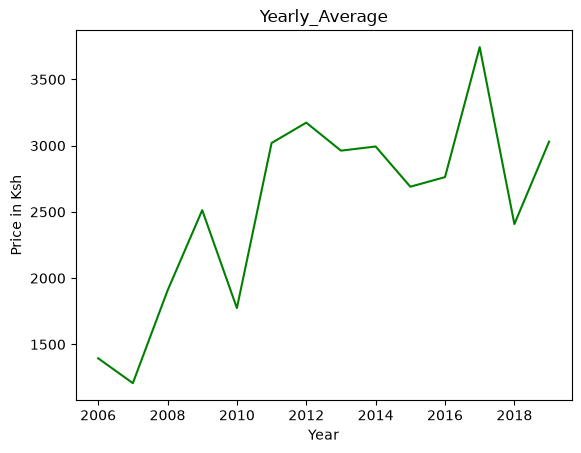

In [60]:
plt.plot(x_values, y_values, color= "green")
plt.title("Yearly_Average")
plt.xlabel("Year")
plt.ylabel("Price in Ksh")
plt.show()

In [66]:
yearly_avg.loc[yearly_avg['yoy_change_kes'].idxmax(), 'year'] # highest rise
yearly_avg.loc[yearly_avg['yoy_change_kes'].idxmin(), 'year'] #highest fall

np.int32(2018)

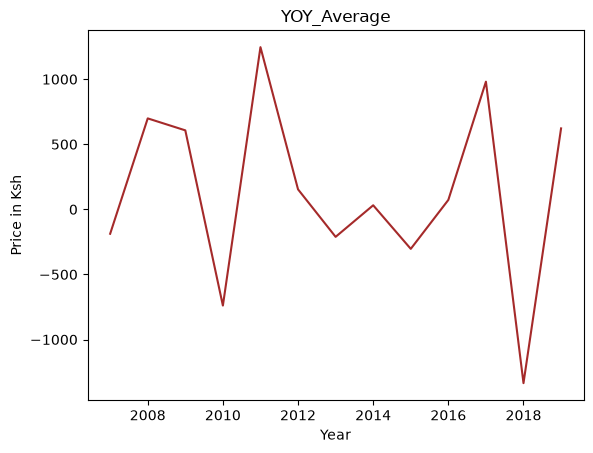

In [69]:
y_values = yearly_avg["yoy_change_kes"]
x_values = yearly_avg["year"]
plt.plot(x_values, y_values, color= "brown")
plt.title("YOY_Average")
plt.xlabel("Year")
plt.ylabel("Price in Ksh")
plt.show()